<a href="https://colab.research.google.com/github/HafizRizqi/PCVK_2026/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HAFIZ RIZQI HERNANDA TI-3C (244107020154) PCVK

# Praktikum Filter

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [15]:

# Fungsi konvolusi manual
def convolution2d(image, kernel):

    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)

    tinggi, lebar = image.shape
    tinggi_kernel, lebar_kernel = kernel.shape

    # Padding agar ukuran hasil sama dengan citra asli
    pad_y = tinggi_kernel // 2
    pad_x = lebar_kernel // 2

    image_pad = np.pad(
        image,
        ((pad_y, pad_y), (pad_x, pad_x)),
        mode='constant',
        constant_values=0
    )

    hasil = np.zeros((tinggi, lebar), dtype=np.float32)

    # Proses konvolusi menggunakan kernel
    for i in range(tinggi_kernel):
        for j in range(lebar_kernel):

            hasil += (
                kernel[i, j]
                * image_pad[
                    i:i + tinggi,
                    j:j + lebar
                ]
            )

    return hasil


In [9]:
# Membaca gambar dari file
img = cv.imread('/content/drive/MyDrive/PCVK/mandrill.tiff')

# Mengubah gambar dari BGR ke grayscale
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

In [16]:
# 2. MENENTUKAN KERNEL FILTER
# ==========================================

# Average Filter 3x3
kernel_average = np.ones((3, 3), dtype=np.float32) / 9


# Low Pass Filter
kernel_lowpass = np.array([
    [1, 1, 1],
    [1, 4, 1],
    [1, 1, 1]
], dtype=np.float32) / 12


# High Pass Filter
kernel_highpass = np.array([
    [-1,  0, 1],
    [-1,  0, 3],
    [-3,  0, 1]
], dtype=np.float32)


# Sharpen Filter
kernel_sharpen = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)


# Emboss Filter
kernel_emboss = np.array([
    [-2, -1, 0],
    [-1,  1, 1],
    [ 0,  1, 2]
], dtype=np.float32)


# Left Sobel Edge Detection
kernel_sobel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
], dtype=np.float32)


# Kernel deteksi tepi sesuai Modul 6
kernel_canny = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)


# Gaussian Blur 21x21
kernel_size = 21
sigma = math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(
    kernel_size,
    sigma
)

kernel_gaussian = (
    gaussian_kernel @ gaussian_kernel.T
)


In [17]:
# 3. MENYIMPAN SEMUA KERNEL
# ==========================================

filter_kernels = {
    "Average Filter": kernel_average,
    "Low Pass Filter": kernel_lowpass,
    "High Pass Filter": kernel_highpass,
    "Sharpen": kernel_sharpen,
    "Emboss": kernel_emboss,
    "Left Sobel Edge Detection": kernel_sobel,
    "Canny Edge Detection": kernel_canny,
    "21x21 Gaussian Blur": kernel_gaussian
}


In [18]:
# 4. MENERAPKAN FILTER PADA CITRA
# ==========================================

hasil_filter = {}

for nama_filter, kernel in filter_kernels.items():

    # Melakukan konvolusi
    hasil = convolution2d(img_gray, kernel)

    # Membatasi intensitas piksel ke rentang 0-255
    hasil_tampil = np.clip(
        hasil, 0, 255
    ).astype(np.uint8)

    # Menyimpan hasil setiap filter
    hasil_filter[nama_filter] = hasil_tampil


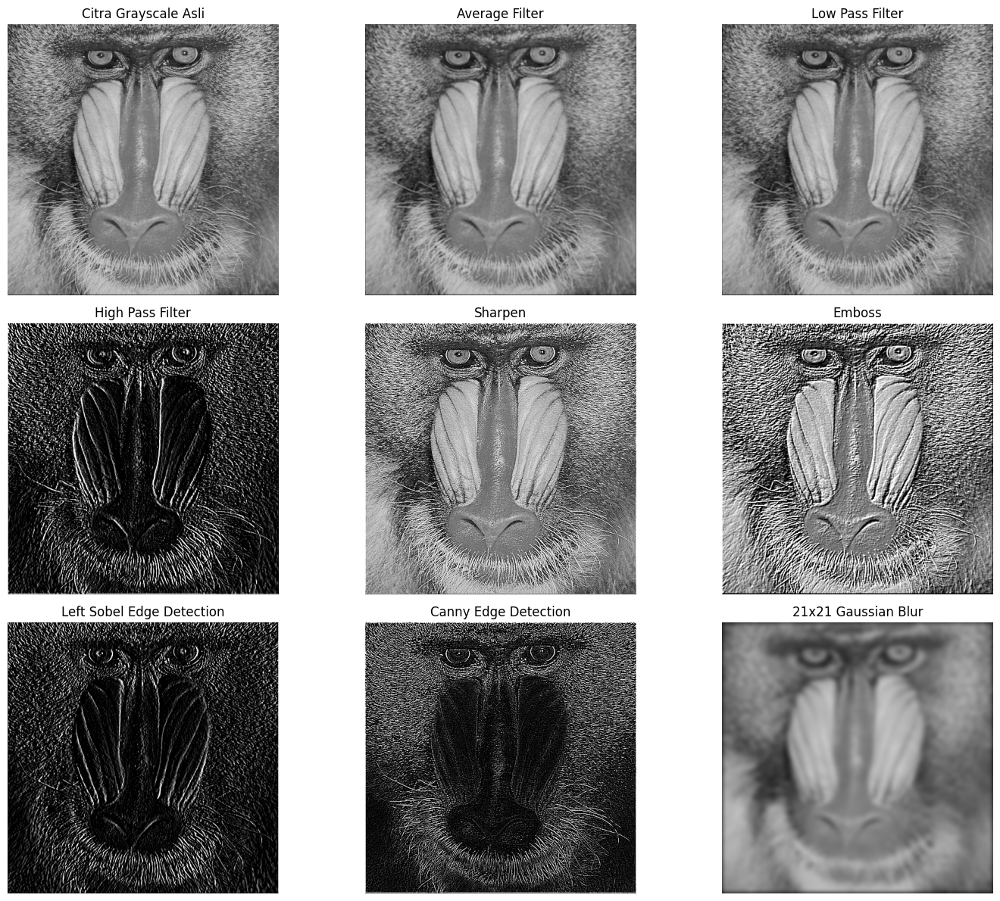

In [19]:
# 5. MENAMPILKAN HASIL FILTER
# ==========================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12)
)

axes = axes.ravel()

# Citra asli
axes[0].imshow(
    img_gray,
    cmap='gray',
    vmin=0,
    vmax=255
)

axes[0].set_title("Citra Grayscale Asli")
axes[0].axis("off")


# Menampilkan semua hasil filter
for indeks, (nama_filter, hasil) in enumerate(
    hasil_filter.items(), start=1
):

    axes[indeks].imshow(
        hasil,
        cmap='gray',
        vmin=0,
        vmax=255
    )

    axes[indeks].set_title(nama_filter)
    axes[indeks].axis("off")


plt.tight_layout()
plt.show()

# Percobaan 1

membuat Filter Gaussian, Sharpen, dan Canny menggunakan library
filter2d dari OpenCV. Filter ini akan kita terapkan pada Image RGB. Pada bagian awal kode terdapat
fungsi show_side_by_side yang digunakan untuk menampilkan gambar secara berdampingan.

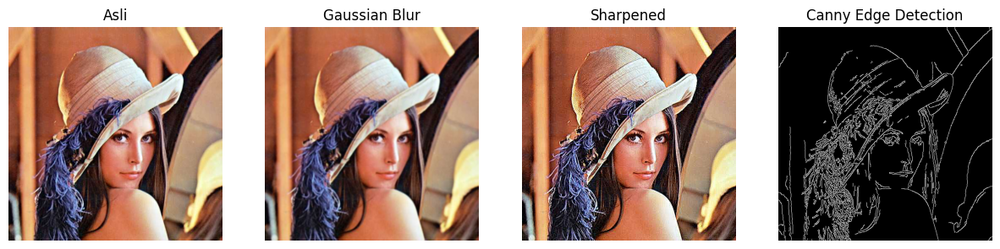

In [32]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread("/content/drive/MyDrive/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])


# Percobaan 2

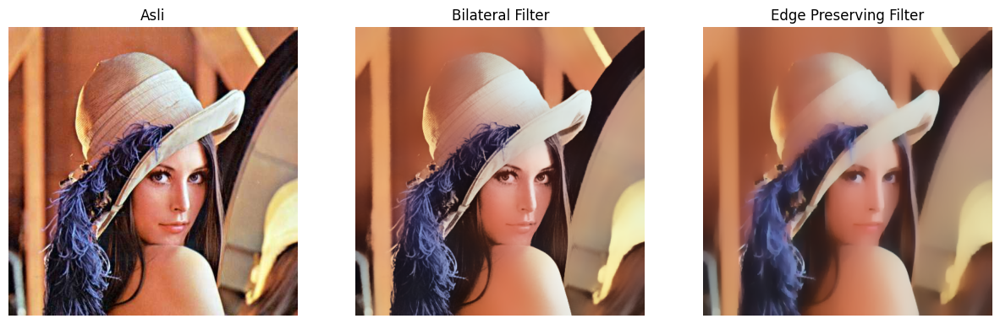

In [33]:
#Filter Modern dari OpenCV
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])


# Percobaan 3

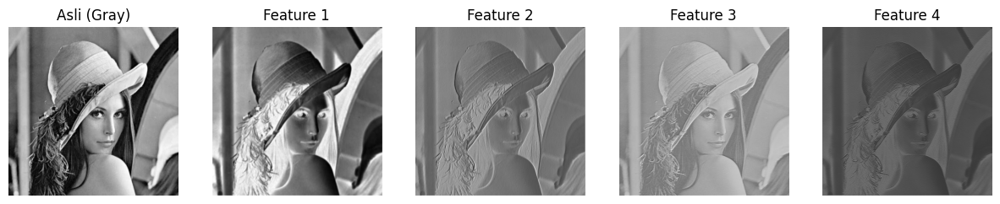

In [36]:
#Filter Feature Map yang digunakan pada CNN, Lakukan running code bagian ini beberapa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])


# Percobaan 4

In [37]:
# =================
# 1. Beauty Filter
# =================

# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # contrast
beta = 15    # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# =================
# 2. Old/Vintage Filter
# =================

# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])

sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)


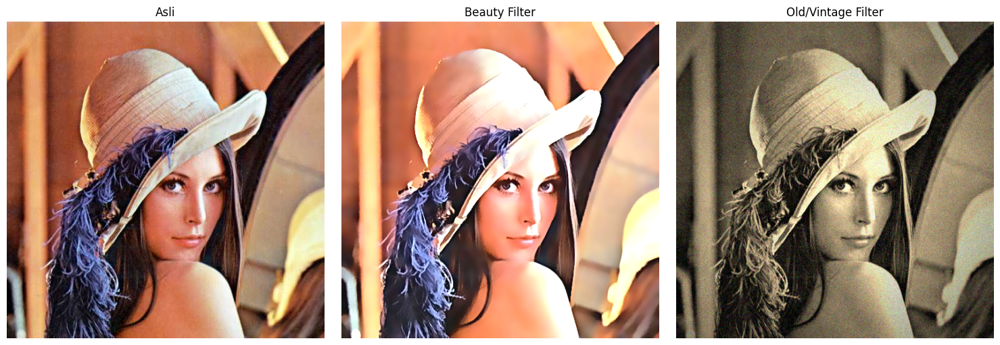

In [38]:
# Mengubah format warna BGR menjadi RGB
# (jika citra dibaca menggunakan cv.imread)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
beauty_rgb = cv.cvtColor(beauty, cv.COLOR_BGR2RGB)
vintage_rgb = cv.cvtColor(old_img, cv.COLOR_BGR2RGB)

# Membuat tampilan 3 gambar berdampingan
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Gambar asli
axes[0].imshow(img_rgb)
axes[0].set_title("Asli")
axes[0].axis("off")

# Hasil Beauty Filter
axes[1].imshow(beauty_rgb)
axes[1].set_title("Beauty Filter")
axes[1].axis("off")

# Hasil Old/Vintage Filter
axes[2].imshow(vintage_rgb)
axes[2].set_title("Old/Vintage Filter")
axes[2].axis("off")

# Merapikan tata letak gambar
plt.tight_layout()
plt.show()

# Percobaan 5

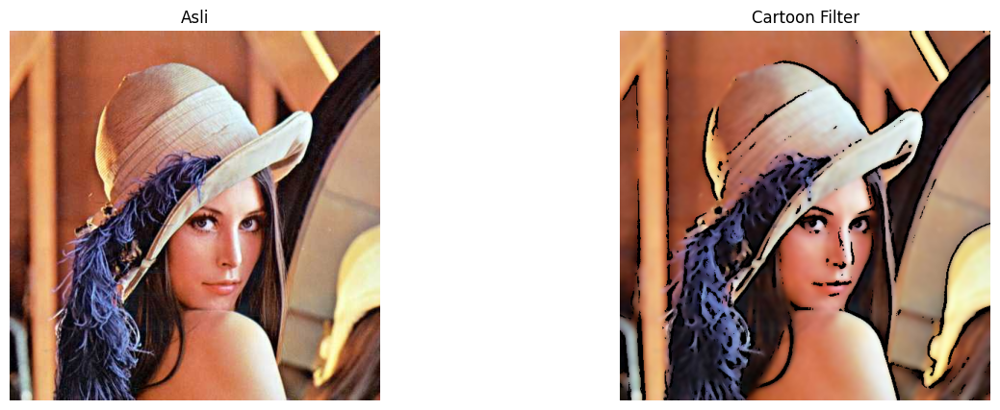

In [39]:
#Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])


# Percobaan 6

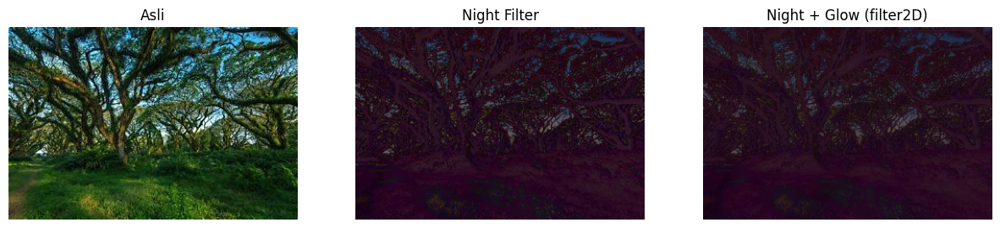

In [40]:
#Night Filter
img = cv.imread("/content/drive/MyDrive/PCVK/djawatan.jpg")
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])


# Percobaan 7

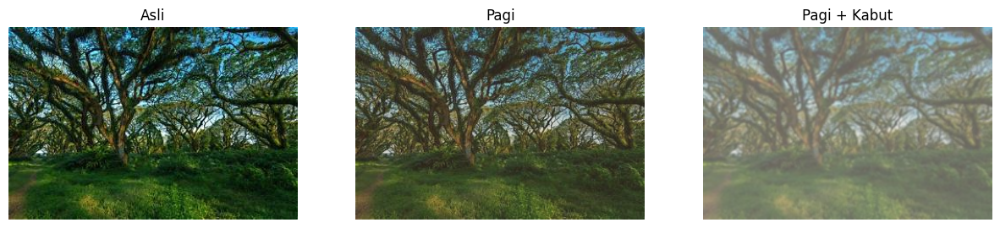

In [41]:
#Filter Suasana pagi dan Kabut
# ============================
# Step 1: Kurangi kontras & cerahkan
# ============================
alpha = 0.9        # contrast
beta = 20          # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# ============================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# ============================
warm_tint = np.full_like(soft, (40, 70, 120))   # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# ============================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# ============================
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T   # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])


# Tugas Analisis

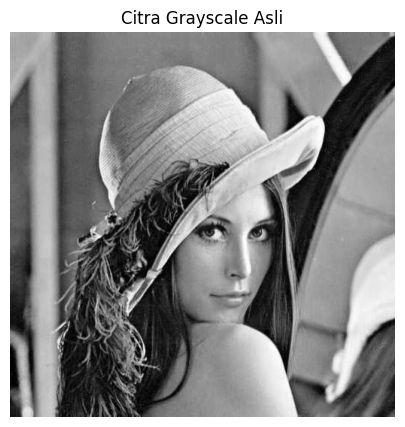

In [42]:
# Membaca kembali citra yang digunakan pada praktikum
task_img = cv.imread("/content/drive/MyDrive/lena.jpg")

# Memastikan citra berhasil dibaca
if task_img is None:
    raise FileNotFoundError(
        "Citra tidak ditemukan. Periksa lokasi file lena.jpg."
    )

# Mengubah citra berwarna menjadi grayscale
task_gray = cv.cvtColor(task_img, cv.COLOR_BGR2GRAY)

# Menampilkan citra grayscale
plt.figure(figsize=(6, 5))
plt.imshow(task_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Grayscale Asli")
plt.axis("off")
plt.show()

Salt and Pepper Noise merupakan gangguan berupa bintik putih dan hitam. Pada kode ini, 6% piksel dipilih secara acak untuk diberi noise, terdiri atas sekitar 3% piksel putih dan 3% piksel hitam.

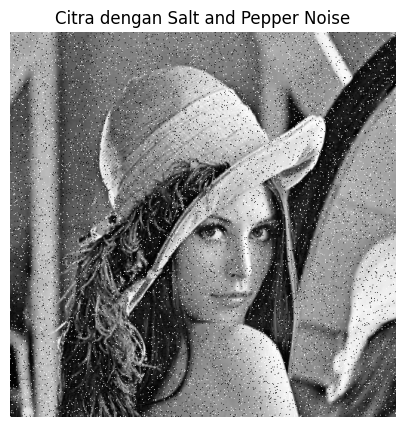

In [43]:
# ==========================================
# MENAMBAHKAN SALT AND PEPPER NOISE
# ==========================================

# Menyalin citra grayscale
noisy_gray = task_gray.copy()

# Membuat generator angka acak agar hasil dapat diulang
rng = np.random.default_rng(42)

# Membuat matriks angka acak sesuai ukuran citra
random_values = rng.random(task_gray.shape)

# Menentukan persentase noise
noise_density = 0.06

# Menentukan posisi bintik putih (Salt)
salt_mask = random_values < (noise_density / 2)

# Menentukan posisi bintik hitam (Pepper)
pepper_mask = (
    (random_values >= noise_density / 2) &
    (random_values < noise_density)
)

# Memberikan nilai putih dan hitam pada piksel terpilih
noisy_gray[salt_mask] = 255
noisy_gray[pepper_mask] = 0

# Menampilkan hasil noise
plt.figure(figsize=(7, 5))
plt.imshow(noisy_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra dengan Salt and Pepper Noise")
plt.axis("off")
plt.show()

Mean Filter mengganti nilai piksel dengan rata-rata piksel pada area 3×3. Median Filter menggantinya dengan nilai tengah dari piksel-piksel dalam area tersebut. Kita menerapkan keduanya pada citra yang sama-sama sudah diberi noise agar hasilnya dapat dibandingkan secara adil.

In [44]:
# ==========================================
# MEAN FILTER DAN MEDIAN FILTER 3x3
# ==========================================

# Mean Filter 3x3
mean_filtered = cv.blur(noisy_gray, (3, 3))

# Median Filter 3x3
median_filtered = cv.medianBlur(noisy_gray, 3)

print("Proses Mean Filter dan Median Filter selesai.")

Proses Mean Filter dan Median Filter selesai.


Empat citra ditampilkan berdampingan, mulai dari citra asli, citra yang terkena noise, hasil Mean Filter, hingga hasil Median Filter.

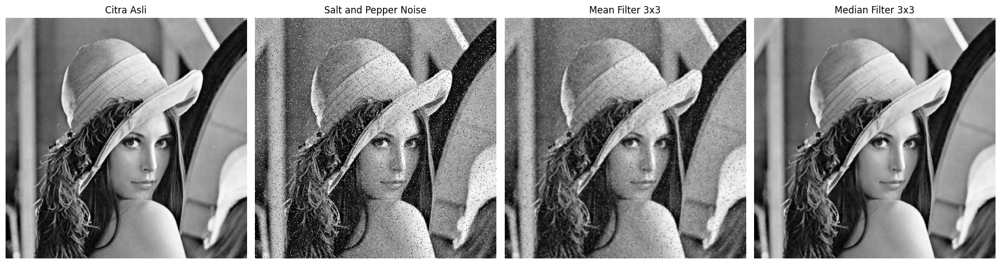

In [46]:
# MENAMPILKAN HASIL TUGAS ANALISIS
images = [
    task_gray,
    noisy_gray,
    mean_filtered,
    median_filtered
]

titles = [
    "Citra Asli",
    "Salt and Pepper Noise",
    "Mean Filter 3x3",
    "Median Filter 3x3"
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# TUGAS EVALUASI

Agar eksperimen dapat langsung dijalankan, kita membuat citra buram dengan Gaussian Blur dari citra asli. Jika kamu memiliki file citra buram sendiri, variabel blurry dapat diganti dengan citra tersebut.

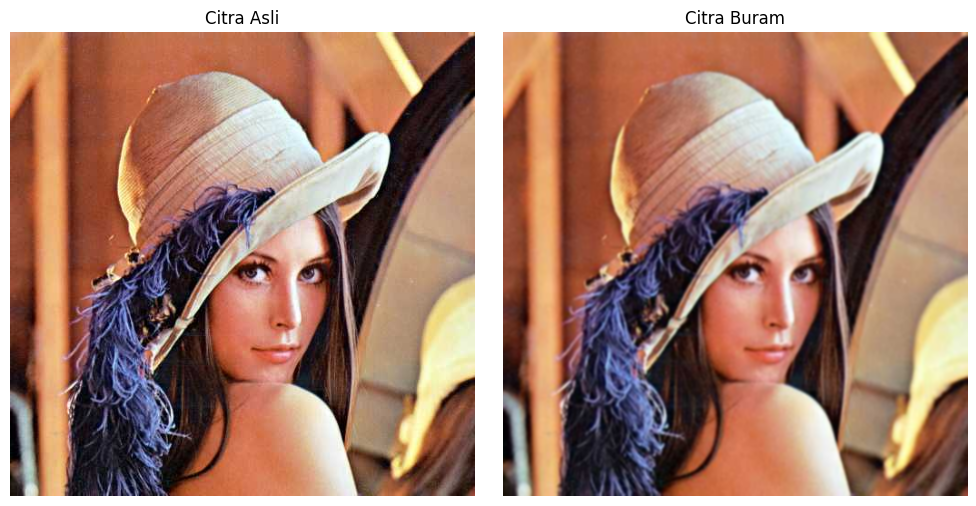

In [47]:
# TUGAS EVALUASI: MEMBUAT CITRA BURAM
# Membuat citra sedikit buram
blurry = cv.GaussianBlur(
    task_img,
    (5, 5),
    1.2
)

# Menampilkan citra asli dan citra buram
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv.cvtColor(task_img, cv.COLOR_BGR2RGB))
axes[0].set_title("Citra Asli")
axes[0].axis("off")

axes[1].imshow(cv.cvtColor(blurry, cv.COLOR_BGR2RGB))
axes[1].set_title("Citra Buram")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Membuat Kernel Sharpening 3×3 dan 5×5

Kernel 3×3 bekerja pada area tetangga yang lebih kecil. Kernel 5×5 mencakup area yang lebih luas. Keduanya dibuat dengan jumlah seluruh koefisien sebesar 1 sehingga intensitas rata-rata pada area konstan cenderung tetap terjaga.

In [48]:
# ==========================================
# KERNEL SHARPENING 3x3
# ==========================================

kernel_sharpen_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)


# ==========================================
# KERNEL SHARPENING 5x5
# ==========================================

kernel_sharpen_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32) / 8

# Menampilkan kernel
print("Kernel Sharpening 3x3:")
print(kernel_sharpen_3x3)

print("\nKernel Sharpening 5x5:")
print(kernel_sharpen_5x5)

Kernel Sharpening 3x3:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Kernel Sharpening 5x5:
[[-0.125 -0.125 -0.125 -0.125 -0.125]
 [-0.125  0.25   0.25   0.25  -0.125]
 [-0.125  0.25   1.     0.25  -0.125]
 [-0.125  0.25   0.25   0.25  -0.125]
 [-0.125 -0.125 -0.125 -0.125 -0.125]]


Menerapkan kedua kernel

Fungsi cv.filter2D() digunakan untuk mengaplikasikan kernel pada citra buram. Hasil perhitungan sementara menggunakan float32 agar nilai negatif dari proses penajaman tidak langsung terpotong. Setelah itu, nilai piksel dibatasi pada rentang 0–255.

In [49]:
# ==========================================
# MENERAPKAN SHARPENING
# ==========================================

# Sharpening dengan kernel 3x3
result_3x3_float = cv.filter2D(
    blurry,
    cv.CV_32F,
    kernel_sharpen_3x3
)

# Sharpening dengan kernel 5x5
result_5x5_float = cv.filter2D(
    blurry,
    cv.CV_32F,
    kernel_sharpen_5x5
)

# Membatasi nilai piksel ke rentang 0-255
sharpened_3x3 = np.clip(
    result_3x3_float, 0, 255
).astype(np.uint8)

sharpened_5x5 = np.clip(
    result_5x5_float, 0, 255
).astype(np.uint8)

print("Proses sharpening selesai.")

Proses sharpening selesai.


Menampilkan hasil dan melakukan evaluasi

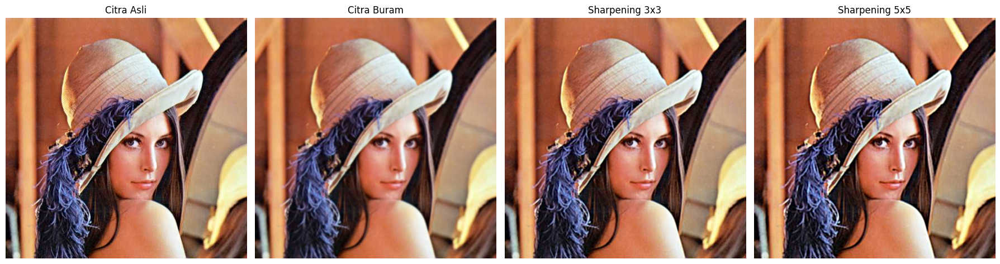

In [51]:
# ==========================================
# MENAMPILKAN HASIL TUGAS EVALUASI
# ==========================================

images = [
    task_img,
    blurry,
    sharpened_3x3,
    sharpened_5x5
]

titles = [
    "Citra Asli",
    "Citra Buram",
    "Sharpening 3x3",
    "Sharpening 5x5"
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, image, title in zip(axes, images, titles):
    image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
    ax.imshow(image_rgb)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# TUGAS KREASI

Membuat fungsi kartun(image)

In [52]:
# ==========================================
# TUGAS KREASI: FUNGSI FILTER KARTUN
# ==========================================

def kartun(image):

    # Memastikan citra tersedia
    if image is None:
        raise ValueError("Citra input tidak boleh kosong.")

    # Jika citra input grayscale, ubah menjadi BGR
    if image.ndim == 2:
        image = cv.cvtColor(image, cv.COLOR_GRAY2BGR)

    # --------------------------------------
    # Langkah 1: Deteksi tepi
    # --------------------------------------

    # Mengubah citra menjadi grayscale
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    # Mengurangi noise sebelum deteksi tepi
    gray_blur = cv.medianBlur(gray, 7)

    # Membentuk mask garis menggunakan Adaptive Thresholding
    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    # --------------------------------------
    # Langkah 2: Menghaluskan warna
    # --------------------------------------

    color_smooth = cv.bilateralFilter(
        image,
        d=9,
        sigmaColor=200,
        sigmaSpace=200
    )

    # --------------------------------------
    # Langkah 3: Menggabungkan warna dan tepi
    # --------------------------------------

    cartoon_image = cv.bitwise_and(
        color_smooth,
        color_smooth,
        mask=edges
    )

    return cartoon_image

Memanggil fungsi kartun

In [53]:
# ==========================================
# MENJALANKAN FUNGSI KARTUN
# ==========================================

cartoon_result = kartun(task_img)

print("Filter kartun berhasil diterapkan.")

Filter kartun berhasil diterapkan.


Menampilkan citra asli dan hasil kartun

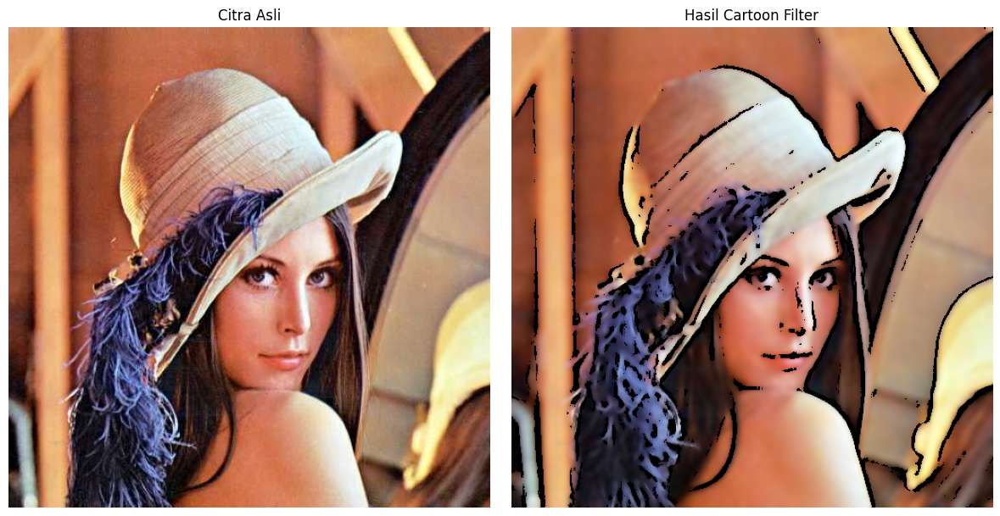

In [55]:
# ==========================================
# MENAMPILKAN HASIL TUGAS KREASI
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Citra asli
axes[0].imshow(
    cv.cvtColor(task_img, cv.COLOR_BGR2RGB)
)
axes[0].set_title("Citra Asli")
axes[0].axis("off")

# Citra dengan filter kartun
axes[1].imshow(
    cv.cvtColor(cartoon_result, cv.COLOR_BGR2RGB)
)
axes[1].set_title("Hasil Cartoon Filter")
axes[1].axis("off")

plt.tight_layout()
plt.show()